# Векторные модели: Word2Vec и BERT

Продолжаем работу из тетрадки про BoW и TF-IDF. Данные те же, что и на прошлой паре. Теперь попробуем готовые векторы слов Word2Vec и контекстную модель BERT, а затем сравним их с уже знакомыми подходами.

## План

1. Готовые векторы слов: Word2Vec.
2. Контекстные векторы: BERT.
3. Сравнение четырёх подходов на одних данных.
4. Практика: тематическая и смысловая близость.


## Подготовка

К библиотекам с прошлой пары добавим библиотеки для Word2Vec и BERT. При первом запуске понадобится интернет; файлы моделей сохранятся в папку `models` и будут использоваться повторно. Лучше выполнить ячейки загрузки моделей заранее.

In [ ]:
# Установим дополнительные библиотеки для Word2Vec и BERT
!pip install -q "gensim>=4.4,<5" "torch>=2.6,<3" "transformers>=4.57,<5" sentencepiece

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 33.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 53.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 58.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics.pairwise import cosine_similarity

import torch
from gensim.models import KeyedVectors
from transformers import AutoTokenizer, AutoModel


Данные те же, что и на прошлой паре. Читаем из `semantic_texts.jsonl` готовые версии: `text_bow_with_stopwords` или `text_bow_without_stopwords` для BoW/TF-IDF, `tokens_w2v` для Word2Vec и исходный `text` для BERT.

In [ ]:
!wget https://raw.githubusercontent.com/hse-ling-python/hse-ling_26-27/refs/heads/main/files/semantic_texts.jsonl
!wget https://raw.githubusercontent.com/hse-ling-python/hse-ling_26-27/refs/heads/main/files/wikipedia_sample.jsonl

--2026-10-14 09:43:55--  https://raw.githubusercontent.com/hse-ling-python/hse-ling_26-27/refs/heads/main/files/semantic_texts.jsonl
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 67648 (66K) [text/plain]
Saving to: ‘semantic_texts.jsonl’

semantic_texts.json 100%[===================>]  66.06K  --.-KB/s    in 0.01s   

2026-10-14 09:43:55 (5.59 MB/s) - ‘semantic_texts.jsonl’ saved [67648/67648]

--2026-10-14 09:43:55--  https://raw.githubusercontent.com/hse-ling-python/hse-ling_26-27/refs/heads/main/files/wikipedia_sample.jsonl
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP req

In [ ]:
path = "semantic_texts.jsonl"
docs = pd.read_json(path, lines=True)
texts = docs["text"].tolist()
# Тот же вариант, что и на прошлой паре; можно выбрать версию со стоп-словами
bow_text_field = "text_bow_without_stopwords"
clean_texts = docs[bow_text_field].tolist()
w2v_tokens = docs["tokens_w2v"].tolist()

In [ ]:
# Нарисуем близость каждой пары текстов (можно не вникать)

similarity_cmap = LinearSegmentedColormap.from_list(
    "blue_white_red", ["#3b4cc0", "white", "#b40426"], N=257
)

def plot_similarity(matrix, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(cosine_similarity(matrix), vmin=-1, vmax=1, cmap=similarity_cmap)
    ax.set(title=title, xlabel="Документ", ylabel="Документ")
    ax.set_xticks(range(len(docs)), docs.title, rotation=90, fontsize=7)
    ax.set_yticks(range(len(docs)), docs.title, fontsize=7)
    for border in [3.5, 7.5, 11.5, 15.5, 19.5]:
        ax.axhline(border, color="black", linewidth=0.5)
        ax.axvline(border, color="black", linewidth=0.5)
    return image

## Готовые векторы слов: word2vec

Существуют методы векторизации, основанные на дистрибутивной семантике. Ее идея заключается в том, что смысл слова определяется его контекстом. Таким образом, похожие слова - это слова, встречающиеся в похожих контекстах.

На подобных принципах основана целая группа моделей:
- __GloVe__: считается матрица совместной встречаемости слов, после чего с помощью алгоритмов уменьшения размерности она преобразуется так, чтобы вектора были определенной длины;
- __word2vec__: это уже нейросеть, при ее обучении на основе корпуса постепенно подбираются коэффициенты (значения в векторах) для каждого слова так, чтобы с помощью них можно было наилучшим образом предсказывать слова по контексту;
- __FastText__: то же, что и word2vec, но на буквенных n-граммах, что помогает работать с незнакомыми словами;
- __AdaGram__: умеет разделять несколько значений у одного слова на основе Байесовского подхода.

Мы остановимся подробнее на Word2Vec, как на наиболее распространенной и единственной (еще может быть FastText) свободно доступной до сих пор. Этот инструмент был разработан группой исследователей Google в 2013 году, руководителем проекта был Томаш Миколов.

Основные работы про Word2Vec:
- [Efficient Estimation of Word Representations in Vector Space](https://arxiv.org/abs/1301.3781)
- [Distributed Representations of Words and Phrases and their Compositionality](https://arxiv.org/abs/1310.4546)

Так как такие модели обычно обучаются на большом объеме текстов, обучать свою долго, дорого и нецелесообразно, поэтому мы будем использовать готовую. В целом, для русского языка готовые модели есть на сайте __rusvectores.org__ (иногда сайту бывает нехорошо и он не работает).

__Что такое word2vec?__

Модель представляет собой словарь вида `слово: вектор`, чаще всего вектор содержит 300 значений (число в какой-то момент было подобрано эмпирически и закрепилось). Причем вектора обладают интересной парой свойств:
- Каждая конкретная координата скорее не имеет понятной человеку интерпретации;
- Вектора в целом при этом позволяют выделять закономерности различной сложности:

<img src="https://towardsdatascience.com/wp-content/uploads/2021/03/15F4TXdFYwqi-BWTToQPIfg.jpeg">

Ещё про механику с картинками [тут](https://habr.com/ru/post/446530/).

__Зачем это нужно?__

+ используется для решения семантических задач
+ подаётся на вход нейронным сетям
+ раньше использовался в Siri, Google Assistant, Alexa, Google Translate, но современным моделям уже однозначно проигрывает...

*Давайте подумаем, для описания каких семантических классов слов дистрибутивная информация особенно важна?*

Несколько интересных статей по дистрибутивной семантике:

* [Turney and Pantel 2010](https://jair.org/index.php/jair/article/view/10640)
* [Lenci 2018](https://www.annualreviews.org/doi/abs/10.1146/annurev-linguistics-030514-125254?journalCode=linguistics)
* [Smith 2019](https://arxiv.org/pdf/1902.06006.pdf)
* [Pennington et al. 2014](https://www.aclweb.org/anthology/D14-1162/)
* [Faruqui et al. 2015](https://www.aclweb.org/anthology/N15-1184/)

__Gensim__

Использовать предобученную модель эмбеддингов или обучить свою можно с помощью библиотеки `gensim`. Вот ее [документация](https://radimrehurek.com/gensim/models/word2vec.html). Вообще-то `gensim` — библиотека для тематического моделирования текстов, но один из компонентов в ней — реализация на python алгоритмов из библиотеки word2vec (которая в оригинале была написана на C++).

Возьмем готовую модель с RusVectōrēs: векторы слов на основе Национального корпуса русского языка. Слова в ней записаны в формате `лемма_ЧАСТЬРЕЧИ`, например `кошка_NOUN`; размер вектора — 300. Описание моделей есть на [сайте проекта](https://rusvectores.org/ru/models/).

Архив довольно большой: скачивание и загрузка в память могут занять несколько минут. Если скачивание прервалось, ячейку можно запустить снова. Если сайт недоступен, можно заранее положить архив с указанным именем в `models`.

In [ ]:
# Скачаем архив; при повторном запуске продолжим с уже загруженного места
w2v_path = "models/ruscorpora_upos_skipgram_300_5_2018.vec.gz"
w2v_url = "https://rusvectores.org/static/models/rusvectores4/RNC/ruscorpora_upos_skipgram_300_5_2018.vec.gz"
!curl -L --fail --create-dirs -C - -o {w2v_path} {w2v_url}

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  190M  100  190M    0     0  22.2M      0  0:00:08  0:00:08 --:--:-- 25.3M


Загрузим модель

In [ ]:
w2v = KeyedVectors.load_word2vec_format(w2v_path, binary=False)

In [ ]:
w2v.vector_size

300

И посмотрим на ту самую кошку

In [ ]:
w2v['кошка_NOUN'][:10]

array([ 0.053885,  0.076832, -0.020836,  0.050466, -0.018344,  0.024962,
        0.022273, -0.069766, -0.067729,  0.026725], dtype=float32)

Посмотрим ближайшие слова: здесь мы получаем пары (слово, близость)

In [ ]:
w2v.most_similar("кошка_NOUN")

[('кот_NOUN', 0.7805721759796143),
 ('собака_NOUN', 0.7084056735038757),
 ('котенок_NOUN', 0.6833623647689819),
 ('мяукать_VERB', 0.661374568939209),
 ('мяукать_NOUN', 0.6479178071022034),
 ('клеточка_PROPN', 0.642410397529602),
 ('тобик_PROPN', 0.6401645541191101),
 ('крыса_NOUN', 0.635063648223877),
 ('котенка_NOUN', 0.629923939704895),
 ('окотиться_VERB', 0.6232213973999023)]

### Как получить вектор целого текста

word2vec дает векторы слов, а нам нужны векторы документов. Самый простой вариант — взять среднее по словам, которые нашлись в словаре. Так в каждом документе получится ровно 300 координат независимо от длины текста.

При таком усреднении порядок слов опять теряется. Незнакомые слова пропускаются, поэтому полезно смотреть на **покрытие словаря**: долю найденных слов среди всех слов текста. Если не нашлось ни одного слова, получится нулевой вектор. Его косинус математически не определен; `scikit-learn` возвращает для него нули. Эти нули не означают, что текст относится к другой теме: модель просто не смогла представить его слова.

In [ ]:
# Усредним готовые векторы слов; ключи лемма_ЧАСТЬРЕЧИ уже записаны в файле
def encode_w2v(items):
    result = []
    for keys in items:
        vectors = [w2v[key] for key in keys if key in w2v]
        vector = np.mean(vectors, axis=0) if vectors else np.zeros(w2v.vector_size)
        result.append(vector)
    return np.asarray(result)

X_w2v = encode_w2v(w2v_tokens)

У каждого текста теперь плотный вектор. Посмотрим на первые шесть координат, а затем сравним тексты между собой. В отличие от мешка слов, у отдельной координаты здесь нет подписи в виде слова.

In [ ]:
# Посмотрим на первые координаты всех текстов
pd.DataFrame(X_w2v[:, :6], index=docs.title).round(3)

,0,1,2,3,4,5
title,,,,,,
food_1,-0.037,-0.018,-0.013,-0.030,-0.004,0.003
food_2,-0.039,0.018,0.007,-0.016,-0.020,-0.015
food_3,-0.025,-0.013,0.003,-0.003,0.016,0.005
food_4,-0.038,0.003,0.001,-0.012,-0.013,0.015
study_1,-0.033,-0.025,0.009,-0.016,0.041,0.047
study_2,-0.019,0.013,0.047,-0.009,0.020,-0.039
study_3,-0.011,-0.009,0.028,-0.037,0.055,0.011
study_4,-0.019,-0.011,0.035,-0.021,0.055,0.026
travel_1,-0.039,0.014,0.009,-0.018,-0.013,-0.020


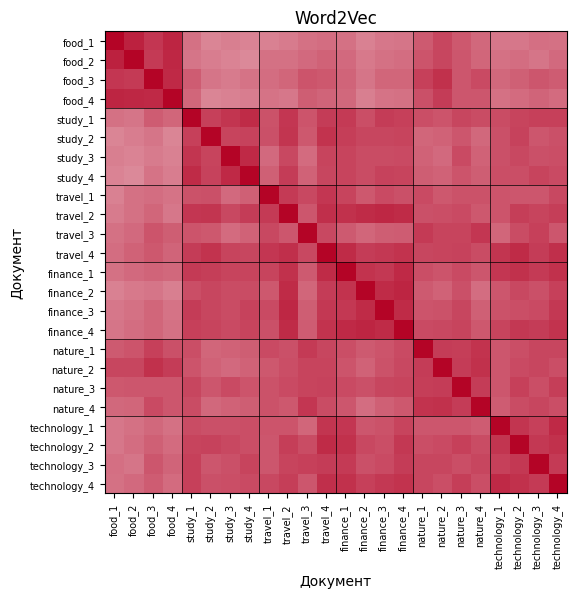

In [ ]:
# Сравним те же тексты с помощью Word2Vec
plot_similarity(X_w2v, "Word2Vec")
plt.show()

In [ ]:
# Проверим, какая часть готовых ключей действительно попала в среднее
def vocabulary_coverage(keys):
    return sum(key in w2v for key in keys) / len(keys) if keys else 0.0

coverage = docs[["doc_id", "title"]].copy()
coverage["доля найденных слов"] = [vocabulary_coverage(keys) for keys in w2v_tokens]
coverage.sort_values("доля найденных слов").head(6)

,doc_id,title,доля найденных слов
8,d09,travel_1,0.500000
17,d18,nature_2,0.500000
14,d15,finance_3,0.521739
12,d13,finance_1,0.533333
6,d07,study_3,0.534884
20,d21,technology_1,0.553191


К сожалению, у word2vec есть несколько минусов. Он
- Не учитывает порядок слов и синтаксические зависимости;
- Не умеет работать с незнакомыми словами (это словарь: нет ключей - нет значений);
- Путает синонимы и антонимы;

In [ ]:
w2v.most_similar('зло_NOUN')

[('добро_NOUN', 0.7334719896316528),
 ('зломя_NOUN', 0.7035925984382629),
 ('зло_VERB', 0.6938475370407104),
 ('насилием_NOUN', 0.6638540029525757),
 ('злу_NOUN', 0.6549335718154907),
 ('злой_NOUN', 0.6526554822921753),
 ('зло_ADV', 0.6483572125434875),
 ('противьтесь_VERB', 0.6258615851402283),
 ('злом_NOUN', 0.620617151260376),
 ('насилие_PROPN', 0.5829303860664368)]

- Не различает омонимы (и чаще всего предпочитает одно из значений);

In [ ]:
w2v.most_similar('замок_NOUN')

[('замокнуть_NOUN', 0.7464022636413574),
 ('замок_ADJ', 0.6631044149398804),
 ('замок_PROPN', 0.6569739580154419),
 ('мондидье_PROPN', 0.6153575778007507),
 ('запираемый_VERB', 0.5956321358680725),
 ('засово_NOUN', 0.5905193090438843),
 ('венсенский_ADJ', 0.588593602180481),
 ('сейфовый_ADJ', 0.5803343057632446),
 ('защелкгиваться_VERB', 0.579129695892334),
 ('отопревать_VERB', 0.575293242931366)]

In [ ]:
w2v.most_similar('лук_NOUN')

[('репчатый_ADJ', 0.7018033862113953),
 ('репчатый_VERB', 0.6678007245063782),
 ('нашинковать_VERB', 0.6440962553024292),
 ('сельдерей_NOUN', 0.6314660906791687),
 ('морковь_NOUN', 0.628654420375824),
 ('лук-порей_ADV', 0.6253951191902161),
 ('чеснок_NOUN', 0.6183842420578003),
 ('помидор_NOUN', 0.6150241494178772),
 ('каперс_NOUN', 0.6140490770339966),
 ('спассеровать_VERB', 0.6125704050064087)]

## Контекстные векторы: BERT

С недостатками word2vec помогают бороться контекстные модели.

У **контекстной модели (contextual model)** вектор слова зависит от всего окружения. В «ключе от квартиры» и «холодном ключе в лесу» одна и та же форма «ключ» может получить разные векторы. Кроме самих слов модель использует информацию об их позициях.

BERT — семейство таких моделей. Через библиотеку `transformers` загрузим небольшую русскоязычную модель `cointegrated/rubert-tiny2` из Hugging Face. Она подходит для работы на CPU, то есть видеокарта для примера не обязательна.

### Текст на входе модели

Здесь используем исходное поле `text`, а не готовые леммы или ключи Word2Vec. Модели нужны обычные тексты с порядком слов и пунктуацией, а ее собственный **токенизатор (tokenizer)** разобьет текст на токены — слова или части слов. Это также позволяет работать со многими словами, которых не было в обучении целиком.

`AutoTokenizer` загружает токенизатор выбранной модели, а `AutoModel` — саму модель.

> Важно! У таких моделей токенайзер всегда идет в паре с моделью. Нельзя просто взять чужой, потому что тогда модель перепутает все слова, которые знает.

In [ ]:
# Загрузим BERT и отключим случайные изменения, нужные только при обучении

model_name = "cointegrated/rubert-tiny2"
tokenizer = AutoTokenizer.from_pretrained(model_name, cache_dir="models/hf")
bert = AutoModel.from_pretrained(model_name, cache_dir="models/hf", add_pooling_layer=False)

# eval - режим применения модели, отключает механики, необходимые только при обучении
bert.eval()

# cuda - это видеокарта, на ней будет сильно быстрее, но скорее всего у вас ее сейчас нет
# и даже если есть, настроить ее для моделей - отдельная непростая задача
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert.to(device)

print("Устройство:", device)
print("Размер вектора:", bert.config.hidden_size)

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/118M [00:00<?, ?B/s]

Устройство: cpu
Размер вектора: 312


Посмотрим на токенизацию

In [ ]:
example = "Из-за обновления ноутбук перестал подключаться к сети."
encoded = tokenizer(example, return_tensors="pt")

Токенизатор возвращает несколько наборов чисел, которые модель использует вместе:

- **`input_ids`** — номера токенов в словаре модели. Токеном может быть слово, часть слова или знак пунктуации. Здесь `2` и `3` — специальные токены `[CLS]` и `[SEP]`, обозначающие начало и конец последовательности.
- **`token_type_ids`** — к какому тексту относится каждый токен. BERT может получать пару текстов: токены первого отмечаются нулями, второго — единицами. Здесь текст один, поэтому везде `0`.
- **`attention_mask`** — какие позиции учитывать: `1` — настоящий токен, `0` — заполнитель (`[PAD]`), добавленный для выравнивания длины текстов. Здесь заполнителей нет, поэтому везде `1`.

Двойные скобки означают, что перед нами набор из **одного текста**, внутри которого **13 токенов**.

In [ ]:
encoded

{'input_ids': tensor([[    2,  5573,    17,   650, 37086, 54310, 38447, 69880,   938,   322,
         16601,    18,     3]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

In [ ]:
# Посмотрим, как токенизатор разделил предложение
pd.DataFrame({
    "токен": tokenizer.convert_ids_to_tokens(encoded["input_ids"][0]),
    "номер": encoded["input_ids"][0].tolist(),
})

,токен,номер
0,[CLS],2
1,Из,5573
2,-,17
3,за,650
4,обновления,37086
5,ноутбук,54310
6,перестал,38447
7,подключать,69880
8,##ся,938
9,к,322


### От векторов токенов к вектору текста

На выходе BERT получаем трехмерный массив: «тексты × токены × координаты». Чтобы сравнивать документы, надо получить по одному вектору на текст. Такое объединение называется **пулингом (pooling)**.

У выбранной модели берем вектор первого специального токена `[CLS]`, как рекомендует [автор модели](https://huggingface.co/cointegrated/rubert-tiny2). RuBERT-tiny2 специально подготовлен для векторов предложений. У произвольного BERT первый токен не обязан давать хорошую семантическую близость, поэтому лучше всегда читать инструкцию от автора. В крайнем случае можно вернуться к старому проверенному методу с усреднением.

Тексты обрабатываем небольшими порциями — **батчами (batches)**. На размер батча влияют два соображения:
- Чем больше батч, тем быстрее вы обработаете весь корпус: модель будет делать все вычисления параллельно, что дает большое ускорение;
- Чем больше батч, тем больше требования к вычислительным ресурсам: вектора для ста текстов параллельно надо где-то хранить и как-то обрабатывать.

И есть еще несколько полезных параметров у токенизатора:
- `padding=True` дополняет короткие последовательности специальными токенами `[PAD]` до длины самой длинной последовательности в батче. Так все строки получаются одинаковой длины;
- `truncation=True` обрезает последовательности, которые превышают допустимую длину;
- `max_length` задает предел для обрезки. Если нужно также дополнять все последовательности именно до этой длины, надо указать `padding="max_length"`, а не `padding=True`;
- `return_tensors` указывает, в каком формате возвращать данные. Значение `"pt"` означает тензоры PyTorch.

В нашем примере `max_length=256`: длинные тексты обрезаются до 256 токенов, а короткие дополняются до длины самого длинного текста в текущем батче после обрезки. Поэтому длина строк может быть меньше 256.

На практике для слишком длинных текстов обычно нужно продумать разбиение на фрагменты, иначе важная для темы информация может оказаться в отброшенной части.

In [ ]:
# Проверим длины до обрезки, чтобы не потерять часть учебных текстов
max_length = 256
lengths = [len(tokenizer(text)["input_ids"]) for text in texts]
print("Максимум токенов в документе:", max(lengths))
assert max(lengths) <= max_length, "Есть длинные тексты: разбейте их на фрагменты"

Максимум токенов в документе: 62


In [ ]:
# Получим по одному нормированному вектору на текст
def encode_bert(items, batch_size=8):
    batches = []
    for start in range(0, len(items), batch_size):
        # токенизируем тексты батчами
        batch = tokenizer(items[start:start + batch_size], padding=True,
                          truncation=True, max_length=max_length, return_tensors="pt")

        # просто поверьте, что это надо, чтобы уметь работать на гпу
        batch = {key: value.to(device) for key, value in batch.items()}

        # отключаем сохранение промежуточных вычислений, которое нужно при обучении
        with torch.no_grad():
            # получаем предсказания от модели (по умолчанию вернет вектора для всех токенов)
            hidden = bert(**batch).last_hidden_state

            # берем только [CLS] токен и нормализуем (просто хорошая привычка)
            vectors = torch.nn.functional.normalize(hidden[:, 0, :], p=2, dim=1)

        batches.append(vectors.cpu().numpy())
    # собираем вектора текстов в одну матрицу или возвращаем пустую, если текстов нет (ну вдруг)
    return np.vstack(batches) if batches else np.empty((0, bert.config.hidden_size))

X_bert = encode_bert(texts)
print("Документов и координат:", X_bert.shape)

Документов и координат: (24, 312)


Посмотрим на первые шесть координат BERT и снова нарисуем близость всех пар. Номера координат Word2Vec и BERT не связаны друг с другом: это разные пространства.

In [ ]:
# Посмотрим на первые координаты всех текстов
pd.DataFrame(X_bert[:, :6], index=docs.title).round(3)

,0,1,2,3,4,5
title,,,,,,
food_1,0.033,0.051,0.016,-0.063,0.036,-0.057
food_2,0.040,0.028,-0.037,-0.032,0.010,0.000
food_3,0.037,0.052,0.002,-0.056,0.033,-0.000
food_4,0.055,-0.016,-0.025,-0.040,0.010,-0.013
study_1,0.016,0.107,0.020,-0.023,-0.042,0.024
study_2,0.044,0.030,-0.046,-0.087,-0.024,0.053
study_3,-0.034,-0.016,0.020,-0.046,-0.076,-0.021
study_4,-0.035,-0.008,-0.036,0.003,-0.099,-0.023
travel_1,0.018,-0.005,-0.077,-0.080,-0.006,-0.014


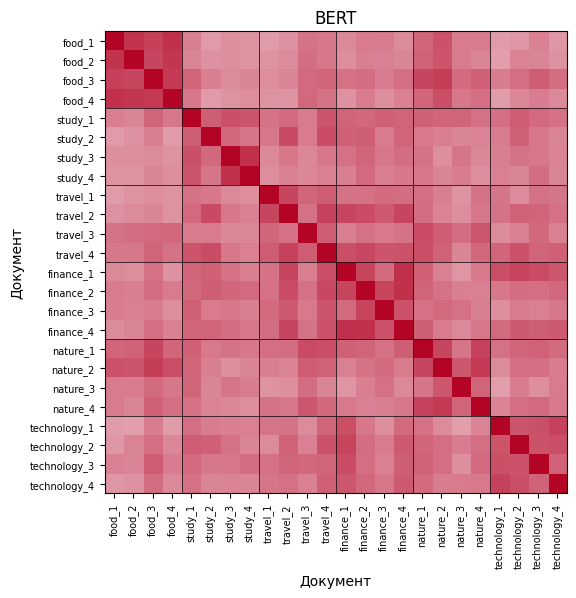

In [ ]:
# Сравним те же тексты с помощью BERT
plot_similarity(X_bert, "BERT")
plt.show()

### Подготовка к общему сравнению

Восстановим BoW и TF-IDF с теми же настройками, что и на прошлой паре, используя готовое поле, выбранное в `bow_text_field`.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

bow = CountVectorizer()
X_bow = bow.fit_transform(clean_texts)
tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(clean_texts)

# Эти функции получают уже подготовленные тексты
def encode_bow(items):
    return bow.transform(items)

def encode_tfidf(items):
    return tfidf.transform(items)

## Сравним подходы на одних данных

Соберем результаты вместе. Сперва посмотрим на тематические группы, затем — на отдельные языковые явления. Одинаковая цветовая шкала помогает читать графики, но абсолютные значения близости между моделями напрямую сравнивать не стоит: прежде всего смотрим на тематические группы.

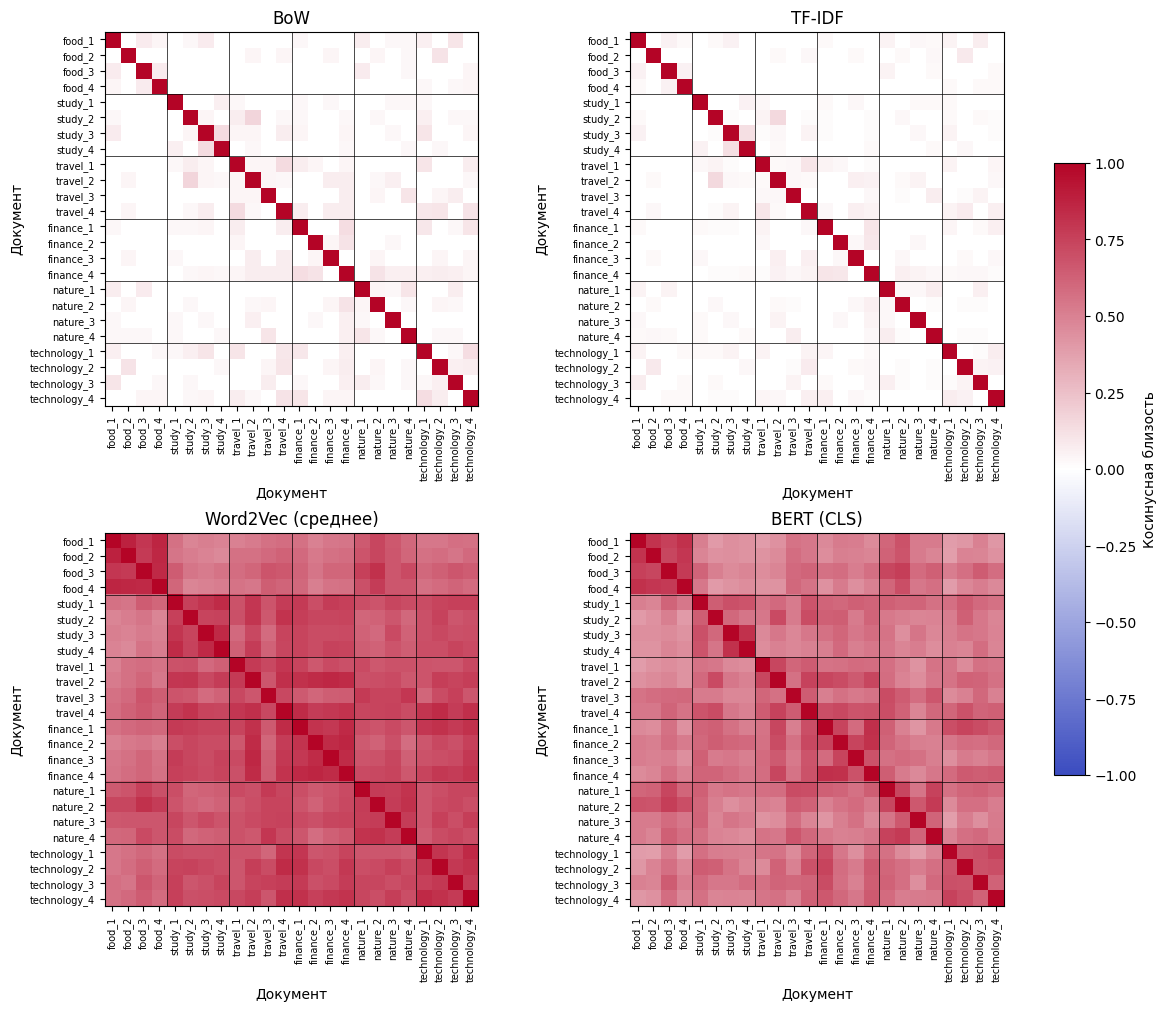

In [ ]:
# Сохраним векторы и способы обработки новых текстов под понятными именами
document_vectors = {"BoW": X_bow, "TF-IDF": X_tfidf,
                    "Word2Vec (среднее)": X_w2v, "BERT (CLS)": X_bert}
encoders = {"BoW": encode_bow, "TF-IDF": encode_tfidf,
            "Word2Vec (среднее)": encode_w2v, "BERT (CLS)": encode_bert}

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
for ax, (name, matrix) in zip(axes.flat, document_vectors.items()):
    image = plot_similarity(matrix, name, ax)
fig.colorbar(image, ax=axes.ravel().tolist(), label="Косинусная близость", shrink=0.7)
plt.show()

### Проверим не только общую тему

Теперь оставим по два коротких текста на каждое явление. Это намеренно маленькие диагностические примеры: на них легче объяснить, что потерялось при векторизации. До этого мы сравнивали полные заметки, а здесь оставим только различие, которое нас интересует.

В синонимичной паре хотелось бы получить высокую близость. В паре с отрицанием или перестановкой действующих лиц ситуация сложнее: тема та же, но утверждения разные. Семантическая близость и логическая эквивалентность — не одно и то же.

In [ ]:
# Диагностические пары и готовые версии текстов для каждой модели
pairs = pd.DataFrame(
    [
        (
            "Формы слова",
            "Студент читает книгу.", "Студенты читают книги.",
            "студент читать книга", "студент читать книга",
            "студент_NOUN читать_VERB книга_NOUN ._PUNCT",
            "студент_NOUN читать_VERB книга_NOUN ._PUNCT",
        ),
        (
            "Перефразировка",
            "Автомобиль нуждается в ремонте.", "Машину нужно починить.",
            "автомобиль нуждаться в ремонт", "машина нужно починить",
            "автомобиль_NOUN нуждаться_VERB в_ADP ремонт_NOUN ._PUNCT",
            "машина_NOUN нужно_X починить_VERB ._PUNCT",
        ),
        (
            "Другое значение",
            "Мастер починил дверной замок.",
            "Туристы осмотрели средневековый замок.",
            "мастер починить дверной замок", "турист осмотреть средневековый замок",
            "мастер_NOUN починить_VERB дверной_ADJ замок_NOUN ._PUNCT",
            "турист_NOUN осмотреть_VERB средневековый_ADJ замок_NOUN ._PUNCT",
        ),
        (
            "Отрицание",
            "Этот билет можно вернуть.", "Этот билет нельзя вернуть.",
            "этот билет можно вернуть", "этот билет нельзя вернуть",
            "этот_DET билет_NOUN можно_X вернуть_VERB ._PUNCT",
            "этот_DET билет_NOUN нельзя_X вернуть_VERB ._PUNCT",
        ),
        (
            "Кто кого",
            "Студент объясняет преподавателю.",
            "Преподаватель объясняет студенту.",
            "студент объяснять преподаватель", "преподаватель объяснять студент",
            "студент_NOUN объяснять_VERB преподаватель_NOUN ._PUNCT",
            "преподаватель_NOUN объяснять_VERB студент_NOUN ._PUNCT",
        ),
        (
            "Другая тема",
            "В кастрюле варится суп.", "Ноутбук подключается к сети.",
            "в кастрюля вариться суп", "ноутбук подключаться к сеть",
            "в_ADP кастрюля_NOUN вариться_VERB суп_NOUN ._PUNCT",
            "ноутбук_NOUN подключаться_VERB к_ADP сеть_NOUN ._PUNCT",
        ),
    ],
    columns=[
        "явление",
        "текст A", "текст B",
        "text_bow_with_stopwords_A", "text_bow_with_stopwords_B",
        "tokens_w2v_A", "tokens_w2v_B",
    ],
)

for side in ("A", "B"):
    pairs[f"tokens_w2v_{side}"] = pairs[f"tokens_w2v_{side}"].str.split()

pairs[["явление", "текст A", "текст B"]]

,явление,текст A,текст B
0,Формы слова,Студент читает книгу.,Студенты читают книги.
1,Перефразировка,Автомобиль нуждается в ремонте.,Машину нужно починить.
2,Другое значение,Мастер починил дверной замок.,Туристы осмотрели средневековый замок.
3,Отрицание,Этот билет можно вернуть.,Этот билет нельзя вернуть.
4,Кто кого,Студент объясняет преподавателю.,Преподаватель объясняет студенту.
5,Другая тема,В кастрюле варится суп.,Ноутбук подключается к сети.


In [ ]:
# Каждая модель получает свою версию тех же текстов
bow_text_field = "text_bow_with_stopwords"

pair_columns = {
    "BoW": (f"{bow_text_field}_A", f"{bow_text_field}_B"),
    "TF-IDF": (f"{bow_text_field}_A", f"{bow_text_field}_B"),
    "Word2Vec (среднее)": ("tokens_w2v_A", "tokens_w2v_B"),
    "BERT (CLS)": ("текст A", "текст B"),
}
pair_scores = pairs[["явление"]].copy()
for name, encode in encoders.items():
    column_a, column_b = pair_columns[name]
    left = encode(pairs[column_a].tolist())
    right = encode(pairs[column_b].tolist())
    pair_scores[name] = np.diag(cosine_similarity(left, right))
pair_scores.round(3)

,явление,BoW,TF-IDF,Word2Vec (среднее),BERT (CLS)
0,Формы слова,1.000,1.000,1.000,0.922
1,Перефразировка,0.000,0.000,0.612,0.828
2,Другое значение,0.289,0.241,0.642,0.730
3,Отрицание,1.000,1.000,1.000,0.896
4,Кто кого,1.000,1.000,1.000,0.976
5,Другая тема,0.000,0.000,0.276,0.574


Посмотрите на строку «Кто кого». После лемматизации набор слов в обоих текстах совпадает, поэтому BoW, TF-IDF и среднее Word2Vec не могут различить эти предложения. BERT получает порядок слов, но это лишь возможность различить ситуации, а не обещание большого расстояния между ними.

С отрицанием действует похожее ограничение. Даже контекстные эмбеддинги могут сильно сближать противоположные утверждения: речь в них об одном предмете. Для проверки противоречий нужна отдельная постановка задачи и проверка качества. А у Word2Vec сначала стоит проверить, попали ли различающие слова в словарь: если «можно» и «нельзя» пропущены, усредняются одни и те же оставшиеся векторы.

## Сравнительная таблица

| Что сравниваем | Мешок слов | TF-IDF | Word2Vec | BERT |
|---|---|---|---|---|
| Откуда берется представление | Частоты слов в тексте | Частоты × редкость в корпусе | Готовые векторы слов | Готовая контекстная модель |
| Что значит координата | Частота слова | Вес слова | Отдельно обычно не интерпретируется | Отдельно обычно не интерпретируется |
| Размер вектора | Размер словаря корпуса | Размер словаря корпуса | 300 у выбранной модели | 312 у выбранной модели |
| Хранение | Разреженная матрица | Разреженная матрица | Плотные векторы | Плотные векторы |
| Разные формы слова | Нужна предобработка | Нужна предобработка | Нужен формат обучающего словаря | Собственный токенизатор, исходный текст |
| Синонимы без общих слов | Не связывает | Не связывает | Может сближать | Может сближать |
| Вектор слова зависит от окружения | Нет | Нет | Нет | Да |
| Порядок слов | Теряется | Теряется | Теряется при усреднении | Учитывается моделью |
| Незнакомое слово | Игнорируется | Игнорируется | Игнорируется | Разбивается на части; качество не гарантировано |
| Что подстраиваем на нашем корпусе | Словарь | Словарь и IDF | Ничего | Ничего |
| Стоимость применения | Обычно низкая | Обычно низкая | Извлечение векторов и среднее | Прогон нейросети |
| Главная ловушка | Совпадение слов вместо смысла | Редкое слово не обязательно важное | Один вектор на разные значения | Близость не доказывает логическое совпадение |
| Где полезно начать | Простой объяснимый baseline | Группы с общей характерной лексикой | Быстрая работа с готовыми векторами | Тематическая близость и перефразировки |

**Baseline** — исходный простой способ решения, с которым сравнивают более сложные. Если TF-IDF решает вашу задачу, усложнение надо обосновать качеством, а не самим фактом использования нейросети.